In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Linear Regression Environment Ready!")

Linear Regression Environment Ready!


In [2]:
# Sample data
area = np.array([500, 700, 900, 1100, 1300, 1500])
price = np.array([15, 20, 25, 30, 35, 40])

# Convert into DataFrame
data = pd.DataFrame({
    "Area": area,
    "Price": price
})

display(data)

,Area,Price
0,500,15
1,700,20
2,900,25
3,1100,30
4,1300,35
5,1500,40


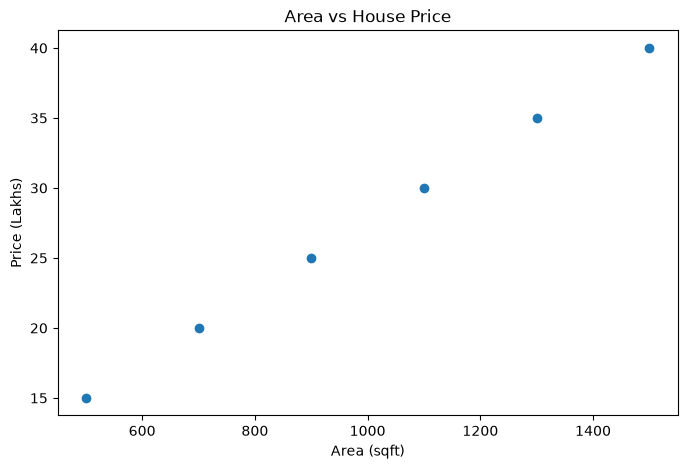

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(data["Area"], data["Price"])

plt.title("Area vs House Price")
plt.xlabel("Area (sqft)")
plt.ylabel("Price (Lakhs)")

plt.show()

In [4]:
# Multiple independent variables
X = pd.DataFrame({
    "Area": [500, 700, 900, 1100, 1300, 1500],
    "Bedrooms": [1, 2, 2, 3, 3, 4],
    "Bathrooms": [1, 1, 2, 2, 3, 3]
})

# Dependent variable
y = np.array([15, 20, 25, 30, 35, 40])

print("Independent Variables:")
display(X)

print("Dependent Variable:")
print(y)

Independent Variables:


,Area,Bedrooms,Bathrooms
0,500,1,1
1,700,2,1
2,900,2,2
3,1100,3,2
4,1300,3,3
5,1500,4,3


Dependent Variable:
[15 20 25 30 35 40]


In [5]:
# Display independent variables
X = pd.DataFrame({
    "Area": [500, 700, 900, 1100, 1300, 1500],
    "Bedrooms": [1, 2, 2, 3, 3, 4],
    "Bathrooms": [1, 1, 2, 2, 3, 3]
})

print("Independent Variables:")
display(X)

print("Number of Features:", X.shape[1])

Independent Variables:


,Area,Bedrooms,Bathrooms
0,500,1,1
1,700,2,1
2,900,2,2
3,1100,3,2
4,1300,3,3
5,1500,4,3


Number of Features: 3


In [6]:
# Define dependent variable
y = np.array([15, 20, 25, 30, 35, 40])

print("Dependent Variable (House Price):")
print(y)

print("Number of Target Values:", len(y))

Dependent Variable (House Price):
[15 20 25 30 35 40]
Number of Target Values: 6


In [7]:
# Define slope and intercept
m = 0.025
c = 2.5

# Input value
x = 1000

# Calculate output
y_pred = m * x + c

print("Input Area:", x)
print("Slope:", m)
print("Intercept:", c)
print("Predicted Price:", y_pred)

Input Area: 1000
Slope: 0.025
Intercept: 2.5
Predicted Price: 27.5


In [8]:
# Train a simple Linear Regression model
X_simple = np.array([[500], [700], [900], [1100], [1300], [1500]])
y_simple = np.array([15, 20, 25, 30, 35, 40])

model = LinearRegression()
model.fit(X_simple, y_simple)

print("Coefficient:", model.coef_[0])

Coefficient: 0.02500000000000001


In [9]:
print("Model Intercept:", model.intercept_)
print("Model Coefficient:", model.coef_[0])

print("\nRegression Equation:")
print(
    f"Price = {model.coef_[0]:.4f} * Area + {model.intercept_:.4f}"
)

Model Intercept: 2.499999999999993
Model Coefficient: 0.02500000000000001

Regression Equation:
Price = 0.0250 * Area + 2.5000


In [10]:
# New house area
new_area = np.array([[1000]])

# Predict house price
predicted_price = model.predict(new_area)

print("New House Area:", new_area[0][0])
print("Predicted House Price:", predicted_price[0])

New House Area: 1000
Predicted House Price: 27.5


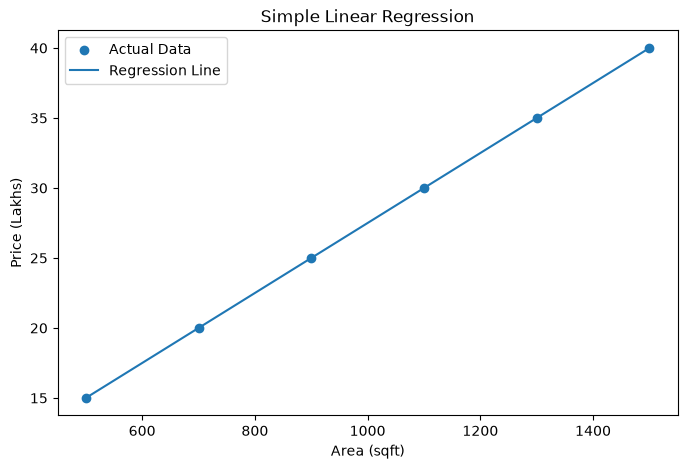

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(X_simple, y_simple, label="Actual Data")

plt.plot(
    X_simple,
    model.predict(X_simple),
    label="Regression Line"
)

plt.title("Simple Linear Regression")
plt.xlabel("Area (sqft)")
plt.ylabel("Price (Lakhs)")
plt.legend()
plt.show()

In [12]:
# Predict values for existing data
y_pred = model.predict(X_simple)

# Calculate residuals
residuals = y_simple - y_pred

results = pd.DataFrame({
    "Actual Price": y_simple,
    "Predicted Price": y_pred,
    "Residual": residuals
})

display(results)

,Actual Price,Predicted Price,Residual
0,15,15.0,3.552714e-15
1,20,20.0,0.000000e+00
2,25,25.0,0.000000e+00
3,30,30.0,-3.552714e-15
4,35,35.0,-7.105427e-15
5,40,40.0,-7.105427e-15


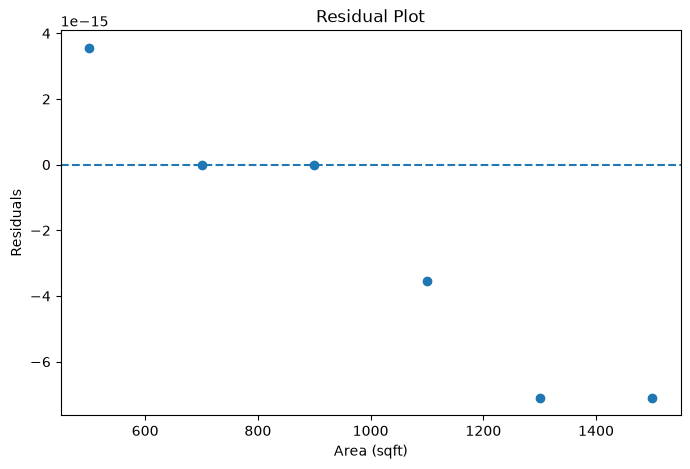

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(X_simple, residuals)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Area (sqft)")
plt.ylabel("Residuals")

plt.show()

In [14]:
# Calculate squared residuals
squared_errors = residuals ** 2

# Calculate Sum of Squared Errors
sse = np.sum(squared_errors)

print("Residuals:", residuals)
print("Squared Errors:", squared_errors)
print("Sum of Squared Errors:", sse)

Residuals: [ 3.55271368e-15  0.00000000e+00  0.00000000e+00 -3.55271368e-15
 -7.10542736e-15 -7.10542736e-15]
Squared Errors: [1.26217745e-29 0.00000000e+00 0.00000000e+00 1.26217745e-29
 5.04870979e-29 5.04870979e-29]
Sum of Squared Errors: 1.262177448353619e-28


In [15]:
# Calculate Mean Squared Error
mse = np.mean((y_simple - y_pred) ** 2)

print("Mean Squared Error:", mse)

Mean Squared Error: 2.103629080589365e-29


In [16]:
# Sample data
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 6, 8, 10], dtype=float)

# Initialize parameters
m = 0.0
c = 0.0

learning_rate = 0.01
epochs = 1000
n = len(x)

# Gradient Descent
for epoch in range(epochs):

    y_pred = m * x + c

    dm = (-2 / n) * np.sum(x * (y - y_pred))
    dc = (-2 / n) * np.sum(y - y_pred)

    m = m - learning_rate * dm
    c = c - learning_rate * dc

print("Learned Slope:", m)
print("Learned Intercept:", c)
print("Final Cost:", np.mean((y - (m * x + c)) ** 2))

Learned Slope: 1.9951803506719779
Learned Intercept: 0.017400463340610635
Final Cost: 5.511055188299796e-05


In [17]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create sample dataset
X = np.array([
    [500], [700], [900], [1100], [1300],
    [1500], [1700], [1900], [2100], [2300]
])

y = np.array([
    15, 20, 25, 30, 35,
    40, 45, 50, 55, 60
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

print("\nMAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Coefficient: 0.025000000000000005
Intercept: 2.499999999999993

MAE: 1.7763568394002505e-15
MSE: 6.310887241768095e-30
R2 Score: 1.0


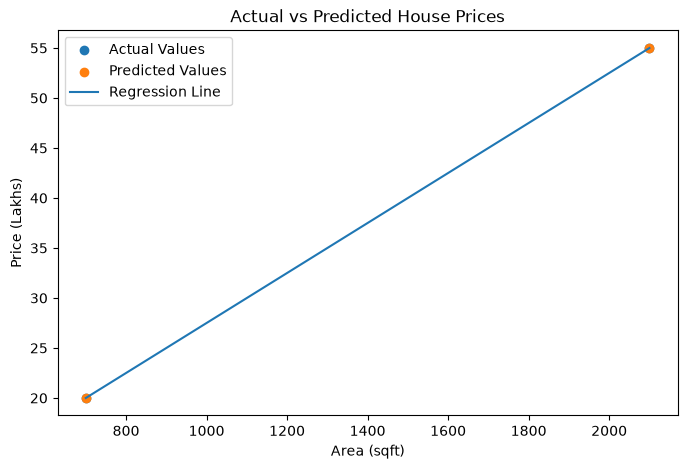

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label="Actual Values")
plt.scatter(X_test, y_pred, label="Predicted Values")

plt.plot(
    X_test.ravel(),
    y_pred,
    label="Regression Line"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Area (sqft)")
plt.ylabel("Price (Lakhs)")
plt.legend()
plt.show()

In [19]:
# Sample dataset
x = np.array([500, 700, 900, 1100, 1300, 1500], dtype=float)
y = np.array([15, 20, 25, 30, 35, 40], dtype=float)

# Calculate means
x_mean = np.mean(x)
y_mean = np.mean(y)

# Calculate slope
numerator = np.sum((x - x_mean) * (y - y_mean))
denominator = np.sum((x - x_mean) ** 2)

m = numerator / denominator

# Calculate intercept
c = y_mean - (m * x_mean)

# Calculate predictions
y_pred_numpy = m * x + c

print("Slope:", m)
print("Intercept:", c)
print("Predictions:", y_pred_numpy)

Slope: 0.025
Intercept: 2.5
Predictions: [15. 20. 25. 30. 35. 40.]
